# CS753 Assignment 1

## Task 1
Implementation of a basic Page Rank algorithm

Set up the modules

In [1]:
import numpy as np
import pandas as pd
import scipy as sp

Some functions for reading and wrangling the data

In [2]:
def read_adjacency_dataset(filename, N):
    with open(filename) as f:
        lines = f.readlines()

    M = sp.sparse.lil_matrix((N, N))

    for l in lines:
        edge_indices = l.strip("\n").split('\t')
        source, dest = int(edge_indices[0]), int(edge_indices[1])
        M[dest, source] = 1 # Source along cols, destinations along rows

    M_csr = M.tocsr()

    return M_csr


def csr_mat_to_col_stochastic(M_csr):
    col_sums = np.array(M_csr.sum(axis=0)).flatten()
    col_sums[col_sums == 0] = 1

    res =  M_csr.multiply(1 / col_sums)

    return res.tocsr()

**(A) Implementing a basic Pagerank algorithm with iterative form**

Get the M matrix

In [3]:
N = 875713

M_csr = read_adjacency_dataset("web-Google-final.txt", N)

M = csr_mat_to_col_stochastic(M_csr)

Function for a basic Page Rank implementation

In [4]:
from timeit import default_timer as timer

def page_rank(M, max_iter=1000, eps=0.02):
    start = timer()
    
    errs = []
    scores = []
    
    N = M.shape[0]

    r_prev = np.ones(shape=(N, 1)) / N

    num_iters = -1
    
    for i in range(1, max_iter):
        r_curr = M.dot(r_prev)
        scores.append(r_curr)
        
        this_error = np.linalg.norm(r_curr - r_prev, ord=1)
        errs.append(this_error)
        
        if this_error < eps:
            num_iters = i
            break
        
        r_prev = r_curr 
    
    if num_iters == -1:
        print(f"Didn't converge in {max_iter} iterations")
    else:
        print(f"Number of iterations: {num_iters}") 
    print(f"Took {timer() - start:.2f} seconds to complete")

    
    return r_prev, scores, errs, num_iters

Now run the iterative method

In [77]:
r, r_scores, errs, i_finish = page_rank(M)

Number of iterations: 49
Took 0.72 seconds to complete


Plot the iteration errors to verify it's converging smoothly

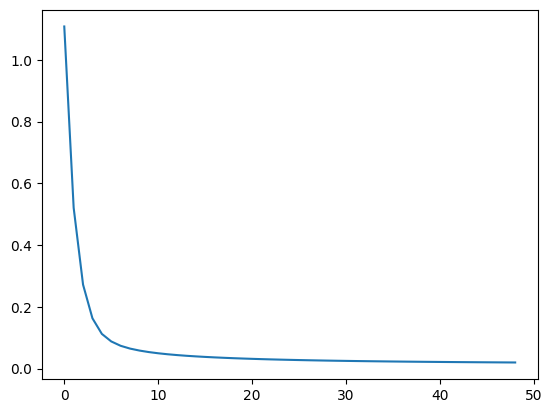

In [6]:
import matplotlib.pyplot as plt

plt.plot(errs)

**(B) extracting top 10 rank scores**

In [78]:
def top_10_ranks(r):
    r_flat = r.flatten()
    r_top_10_IDs = np.argsort(r_flat)[-10:]
    r_top_10_scores = r_flat[r_top_10_IDs]
    
    return r_top_10_IDs, r_top_10_scores

In [79]:
r_top_10_IDs, r_top_10_scores = top_10_ranks(r)

Quickly write the results to Latex for my report

In [80]:
import pandas as pd

def top_ranks_to_latex(top_IDs, top_scores):
    df = pd.DataFrame({
        "Node ID": top_IDs,
        "Node Score": top_scores
    })
    
    df_tex = df.to_latex(index=False, float_format="%.2e")
    print(df_tex)
    
top_ranks_to_latex(r_top_10_IDs, r_top_10_scores)   

\begin{tabular}{rr}
\toprule
Node ID & Node Score \\
\midrule
41909 & 2.41e-04 \\
1536 & 2.49e-04 \\
791675 & 2.95e-04 \\
865192 & 3.20e-04 \\
577518 & 3.60e-04 \\
779617 & 4.28e-04 \\
370344 & 5.14e-04 \\
544138 & 5.14e-04 \\
24576 & 5.14e-04 \\
747106 & 5.30e-04 \\
\bottomrule
\end{tabular}



Print out the top 10 nodes and their scores

In [81]:
print("Top 10 IDs")
print(r_top_10_IDs)
print("Top 10 Scores")
print(r_top_10_scores)

Top 10 IDs
[ 41909   1536 791675 865192 577518 779617 370344 544138  24576 747106]
Top 10 Scores
[0.00024116 0.00024918 0.00029454 0.00031989 0.00035961 0.00042832
 0.00051429 0.00051429 0.00051429 0.00052984]


## Task 2

**(A) Finding dead-end nodes**
* Virtually comes down to finding the nodes with no outgoing links. Can simply do the sum down the columns to identify these nodes

Finding the number of dead ends

In [84]:
num_dead_end_nodes = np.sum(np.sum(M, axis=0) == 0)
print(f"The number of dead-end nodes was {num_dead_end_nodes}")

The number of dead-end nodes was 187880


**(B) Calculating leaked page rank scores**

In [85]:
r_scores = np.array(r_scores)
total_r_per_iteration = np.sum(r_scores, axis=1).reshape((len(r_scores)))
r_totals = np.append([1], total_r_per_iteration) # To account for initial r
leaked_scores_per_iteration = np.abs(np.diff(r_totals))

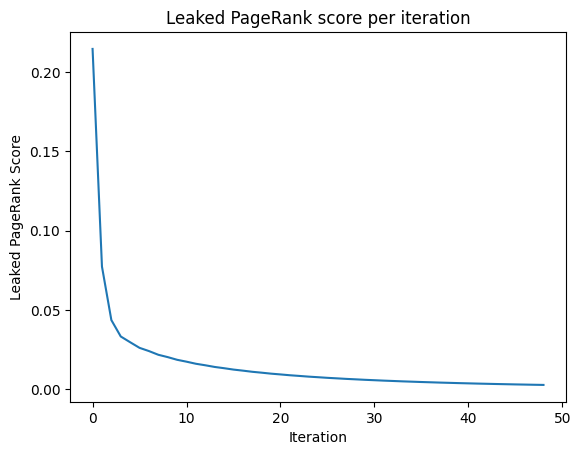

In [86]:
plt.plot(leaked_scores_per_iteration)
plt.title("Leaked PageRank score per iteration")
plt.xlabel("Iteration")
plt.ylabel("Leaked PageRank Score")
plt.savefig("leaked_page_rank.png", dpi=300)

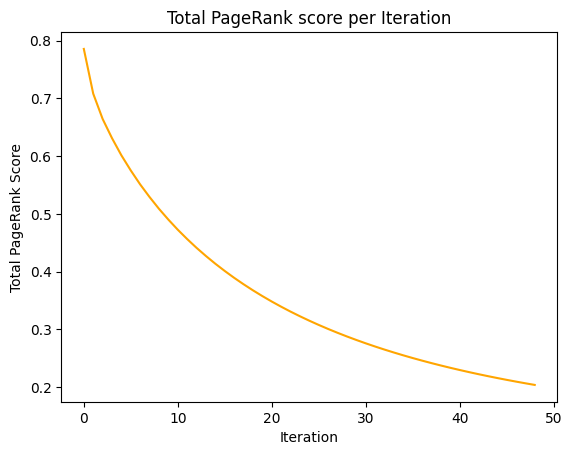

In [87]:
plt.plot(total_r_per_iteration, color="orange")
plt.title("Total PageRank score per Iteration")
plt.xlabel("Iteration")
plt.ylabel("Total PageRank Score")
plt.savefig("total_page_rank.png", dpi=300)

# Task 3

**(A) Adding teleportation**

In [88]:
def page_rank_improved(M, max_iter=1000, eps=0.02, beta=0.9):
    """
    Does page rank to handle both dead ends and spider traps
    """

    N = M.shape[0]
    r_prev = np.ones(shape=(N, 1)) / N
    
    errs = []
    scores = []
    
    num_iters = -1
    
    start = timer()

    for i in range(max_iter):
        r_curr = beta * M.dot(r_prev) # Step 1
        
        S = np.sum(r_curr) # Step 2
        
        scores.append(r_curr)
        
        r_curr = r_curr + (1 - S) / N # Step 3
        
        this_error = np.linalg.norm(r_curr - r_prev, ord=1)
        errs.append(this_error)

        if this_error < eps:
            num_iters = i+1
            break

        r_prev = r_curr

    if num_iters == -1:
            print(f"Didn't converge in {max_iter} iterations")
    else:
        print(f"Number of iterations: {num_iters}")
    print(f"Took {timer() - start:.2f} seconds to complete")

    return r_prev, scores, errs, num_iters

**(B) Running teleportation code**

In [89]:
r_improved, scores_improved, errs_improved, i_finish_improved = page_rank_improved(M)

Number of iterations: 10
Took 0.18 seconds to complete


In [90]:
top_ranks_to_latex(*top_10_ranks(r_improved))

\begin{tabular}{rr}
\toprule
Node ID & Node Score \\
\midrule
605856 & 7.74e-04 \\
32163 & 7.87e-04 \\
558791 & 8.15e-04 \\
486980 & 8.24e-04 \\
504140 & 8.46e-04 \\
384666 & 8.56e-04 \\
163075 & 9.92e-04 \\
537039 & 1.00e-03 \\
597621 & 1.01e-03 \\
41909 & 1.04e-03 \\
\bottomrule
\end{tabular}



In [91]:
beta_vals = [1, 0.9, 0.8, 0.7, 0.6]
iterations_vals = []
beta_r_scores = []

for B in beta_vals:
    r, _, _, iters = page_rank_improved(M, beta=B)

    beta_r_scores.append(r)
    
    iterations_vals.append(iters)
    
    print(f"\nFor beta {B}, num iterations is: {iters}")

    print(f"mean rank: {np.mean(r):.2e}\n")


Number of iterations: 63
Took 1.39 seconds to complete

For beta 1, num iterations is: 63
mean rank: 1.14e-06

Number of iterations: 10
Took 0.19 seconds to complete

For beta 0.9, num iterations is: 10
mean rank: 1.14e-06

Number of iterations: 7
Took 0.13 seconds to complete

For beta 0.8, num iterations is: 7
mean rank: 1.14e-06

Number of iterations: 5
Took 0.09 seconds to complete

For beta 0.7, num iterations is: 5
mean rank: 1.14e-06

Number of iterations: 5
Took 0.08 seconds to complete

For beta 0.6, num iterations is: 5
mean rank: 1.14e-06



Plotting beta values and their convergence rates

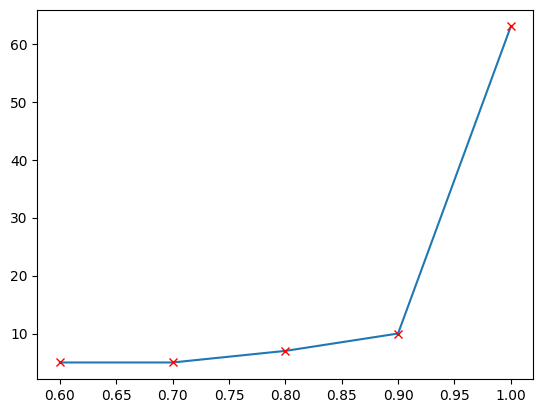

In [92]:
plt.plot(beta_vals, iterations_vals, marker="x", markeredgecolor = "red")

Clearly what is happening that an increase of the Beta value increases the number of iterations for the algo to finish

Writing results to latex for my report

In [93]:
df_beta = pd.DataFrame({
    "Teleportation Probability ($\\beta$)": beta_vals,
    "Iterations to Converge": iterations_vals
})

tex = df_beta.to_latex(index=False, float_format="%.1f")

print(tex)

\begin{tabular}{rr}
\toprule
Teleportation Probability ($\beta$) & Iterations to Converge \\
\midrule
1.0 & 63 \\
0.9 & 10 \\
0.8 & 7 \\
0.7 & 5 \\
0.6 & 5 \\
\bottomrule
\end{tabular}

